# Bayesian Modelling of Infectious-Disease Case Counts

**Research question:** How can Bayesian methods estimate trends in reported
disease cases, and how certain are those estimates?

**Plan**
1. Check the method on *simulated* data where the true answer is known.
2. Prepare and plot real weekly case counts.
3. Fit a Bayesian **Poisson** model (log-linear growth) with MCMC.
4. Check convergence (trace plots, R-hat, effective sample size).
5. Posterior predictive checks -> Poisson is too narrow -> fit a
   **Negative Binomial** model and compare the two with LOO.
6. **Under-reporting:** add a detection probability and show what the data
   can and cannot tell us (identifiability).
7. Interpretation, limitations and uncertainty.

Tools: Python, pandas, NumPy, PyMC, ArviZ, Matplotlib.

In [89]:
import os
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy.stats import gaussian_kde

import sys
if hasattr(sys.stdout, "reconfigure"):   # lets Windows terminals print symbols like k̂
    sys.stdout.reconfigure(encoding="utf-8")

RNG_SEED = 2026
rng = np.random.default_rng(RNG_SEED)

# Sampler settings used for every model. cores=1 keeps things reliable on
# Windows; increase it if multiprocessing works on your machine.
SAMPLE_KW = dict(draws=1000, tune=1000, chains=4, cores=1, target_accept=0.95,
                 random_seed=RNG_SEED, progressbar=False)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# ---- Which country to analyse -------------------------------------------
# Change COUNTRY here (or set the COUNTRY environment variable). The name must
# match Our World in Data, e.g. "Bangladesh", "Canada".
# Each window covers ONE growth phase of the epidemic in that country.
COUNTRY = os.environ.get("COUNTRY", "Bangladesh")
WINDOWS = {
    "Bangladesh": ("2020-04-15", "2020-06-28"),     # first wave, before the plateau
}
START, END = WINDOWS.get(COUNTRY, ("2020-04-15", "2020-06-28"))
TAG = COUNTRY.replace(" ", "_")

FIG_DIR = Path("figures") / TAG
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Save a figure to figures/ so it can be shown in the README."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


def draws(idata, var, group="posterior"):
    """All MCMC draws of one variable as a NumPy array.
    Shape: (n_draws,) for scalars, or (n_draws, n_weeks) for vectors."""
    arr = np.asarray(idata[group][var].values)
    return arr.reshape(-1, *arr.shape[2:])


def summarize(idata, var_names):
    """Posterior mean, sd, 95% HDI, R-hat and effective sample size."""
    return az.summary(idata, var_names=var_names, ci_prob=0.95, ci_kind="hdi")


def density(ax, x, **kwargs):
    """Smooth density curve (kernel density estimate) of samples x."""
    kde = gaussian_kde(x)
    grid = np.linspace(*np.percentile(x, [0.5, 99.5]), 300)
    ax.plot(grid, kde(grid), **kwargs)


def plot_trace(idata, var_names, name):
    """Left: posterior density per chain. Right: draws per chain over time."""
    fig, axes = plt.subplots(len(var_names), 2, figsize=(11, 2.4 * len(var_names)),
                             squeeze=False)
    for row, var in zip(axes, var_names):
        chains = np.asarray(idata["posterior"][var].values)  # (chain, draw)
        for c, chain in enumerate(chains):
            density(row[0], chain, lw=1, label=f"chain {c}")
            row[1].plot(chain, lw=0.5, alpha=0.8)
        row[0].set_title(f"{var}: density by chain")
        row[1].set_title(f"{var}: trace")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    save(fig, name)

## 1. The model

For week $t$ (centred so that $t=0$ is the middle of the window):

$$y_t \sim \text{Poisson}(\mu_t), \qquad \log \mu_t = \alpha + \beta t$$

* $\alpha$ – log of the expected weekly cases in the middle week.
* $\beta$ – weekly growth rate on the log scale.
  $e^{\beta}$ is the week-to-week multiplication factor, and if
  $\beta>0$ the **doubling time** is $\log 2 / \beta$ weeks.

**Priors (weakly informative):**
* $\alpha \sim N(\log \bar y,\; 2)$ – centred on the observed average level,
  but wide enough to allow a level 7x larger or smaller.
  (Using the data to centre a prior is a mild shortcut; say so in the write-up.)
* $\beta \sim N(0,\; 0.5)$ – growth or decline of more than ~2.7x per week is
  unlikely a priori.

The model is wrapped in a function so the same code fits simulated and real data.

In [90]:
def build_model(y, family="poisson", detection_prior=None):
    """Log-linear growth model for weekly counts.

    family: "poisson" or "negbin".
    detection_prior: None, or (a, b) for a Beta(a, b) prior on the
        detection probability p (section 7).
    """
    y = np.asarray(y)
    t = np.arange(len(y)) - (len(y) - 1) / 2  # centred week index

    with pm.Model(coords={"week": np.arange(len(y))}) as model:
        alpha = pm.Normal("alpha", mu=np.log(y.mean()), sigma=2)
        beta = pm.Normal("beta", mu=0, sigma=0.5)

        # Expected number of TRUE cases per week
        mu_true = pm.Deterministic("mu_true", pm.math.exp(alpha + beta * t),
                                   dims="week")

        if detection_prior is None:
            mu_reported = mu_true          # assume every case is reported
        else:
            p = pm.Beta("p", *detection_prior)
            mu_reported = p * mu_true      # only a fraction p is reported

        if family == "poisson":
            pm.Poisson("y", mu=mu_reported, observed=y, dims="week")
        else:
            # Var = mu + mu^2 / phi. A HalfNormal prior on 1/phi shrinks
            # towards the Poisson model (1/phi = 0).
            inv_phi = pm.HalfNormal("inv_phi", sigma=1)
            pm.NegativeBinomial("y", mu=mu_reported, alpha=1 / inv_phi,
                                observed=y, dims="week")

        pm.Deterministic("doubling_time", np.log(2) / beta)
    return model


def fit(model):
    with model:
        idata = pm.sample(**SAMPLE_KW)
        pm.compute_log_likelihood(idata, progressbar=False)  # needed for LOO
        pm.sample_posterior_predictive(idata, extend_inferencedata=True,
                                       random_seed=RNG_SEED, progressbar=False)
    return idata

## 2. Sanity check on simulated data

Before trusting a model on real data, check that it can recover parameters
we chose ourselves. We simulate 14 weeks with $\alpha = 6$ (≈400 cases/week
mid-window) and $\beta = 0.15$ (≈16% growth per week, doubling every ~4.6 weeks).

In [91]:
TRUE_ALPHA, TRUE_BETA = 6.0, 0.15
n_weeks = 14
t_sim = np.arange(n_weeks) - (n_weeks - 1) / 2
y_sim = rng.poisson(np.exp(TRUE_ALPHA + TRUE_BETA * t_sim))

idata_sim = fit(build_model(y_sim, "poisson"))
print(summarize(idata_sim, ["alpha", "beta"]))
print(f"True values: alpha = {TRUE_ALPHA}, beta = {TRUE_BETA}")

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.
Sampling: [y]


         mean      sd hdi95_lb hdi95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
alpha   5.999  0.0143        6        6     1897     2151  1.00   0.00033  0.00023
beta   0.1485  0.0033     0.14     0.15     1859     2083  1.00   7.7e-05  5.4e-05
True values: alpha = 6.0, beta = 0.15


Both true values should fall inside the 95% credible intervals
(the two HDI columns of the summary table). If they do, the code and model work as intended.

## 3. Real data

**Default source:** Our World in Data COVID-19 dataset (daily new cases by
country), aggregated to weekly totals. Record the download date in your README.

The country's rows are saved to `data/cases_<Country>.csv` on first run and
reused after that. To use your own data, save a CSV there with columns
`date` and `cases`.

The window (set at the top with COUNTRY) covers **one growth phase**. A
straight line on the log scale cannot describe a whole wave that rises and falls.

In [92]:
OWID_URL = ("https://catalog.ourworldindata.org/garden/covid/latest/"
            "compact/compact.csv")
LOCAL_CSV = Path(f"data/cases_{TAG}.csv")


def load_cases():
    if LOCAL_CSV.exists():
        df = pd.read_csv(LOCAL_CSV, parse_dates=["date"])
        source = f"local file {LOCAL_CSV}"
    else:
        df = pd.read_csv(OWID_URL, usecols=["country", "date", "new_cases"],
                         parse_dates=["date"])
        df = df[df["country"] == COUNTRY].rename(columns={"new_cases": "cases"})
        source = f"Our World in Data ({COUNTRY})"
        LOCAL_CSV.parent.mkdir(exist_ok=True)
        df[["date", "cases"]].to_csv(LOCAL_CSV, index=False)  # keep a copy
    df = df[(df["date"] >= START) & (df["date"] <= END)]
    weekly = (df.set_index("date")["cases"].clip(lower=0)
                .resample("W-SUN").sum().astype(int))
    # Drop partial first/last weeks so every week has 7 days of data
    return weekly.iloc[1:-1], source


weekly, source = load_cases()
print(f"Source: {source}\n{len(weekly)} weeks\n")
print(weekly)

Source: local file data\cases_Bangladesh.csv
9 weeks

date
2020-04-26     2960
2020-05-03     4039
2020-05-10     5202
2020-05-17     7611
2020-05-24    11342
2020-05-31    13543
2020-06-07    18616
2020-06-14    21751
2020-06-21    24786
Freq: W-SUN, Name: cases, dtype: int64


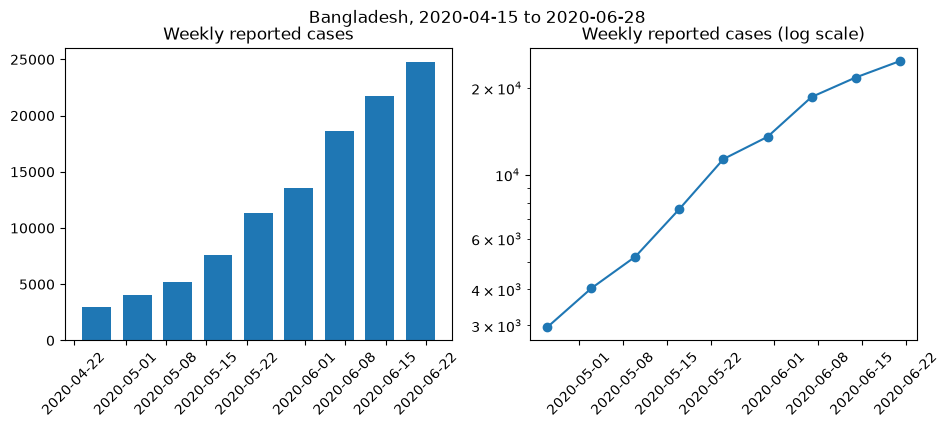

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(weekly.index, weekly.values, width=5)
axes[0].set_title("Weekly reported cases")
axes[1].plot(weekly.index, weekly.values, "o-")
axes[1].set_yscale("log")
axes[1].set_title("Weekly reported cases (log scale)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle(f"{COUNTRY}, {START} to {END}")
save(fig, "01_data")

If the log-scale plot looks roughly like a straight line, the log-linear model
is a reasonable starting point.

## 4. Poisson model: fit and convergence diagnostics

In [83]:
y = weekly.values
idata_pois = fit(build_model(y, "poisson"))

print(summarize(idata_pois, ["alpha", "beta", "doubling_time"]))

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta]
e:\CANADA\bayesian-case-counts\.venv\Lib\site-packages\pymc\step_methods\hmc\quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.
Sampling: [y]


                  mean       sd hdi95_lb hdi95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
alpha           9.1986   0.0036      9.2      9.2     1532     1859  1.00   9.3e-05  5.2e-05
beta           0.25708  0.00131     0.25     0.26     1492     1932  1.00   3.4e-05  2.1e-05
doubling_time   2.6963   0.0137      2.7      2.7     1492     1932  1.00   0.00036  0.00022


**How to read the diagnostics**
* `r_hat` – compares chains. Values ≤ 1.01 mean the chains agree.
* `ess_bulk`, `ess_tail` – effective number of independent draws.
  Several hundred or more is enough for stable means and intervals.
* Trace plots (below) should look like "fuzzy caterpillars" with all chains
  overlapping, and the density plots for each chain should look alike.

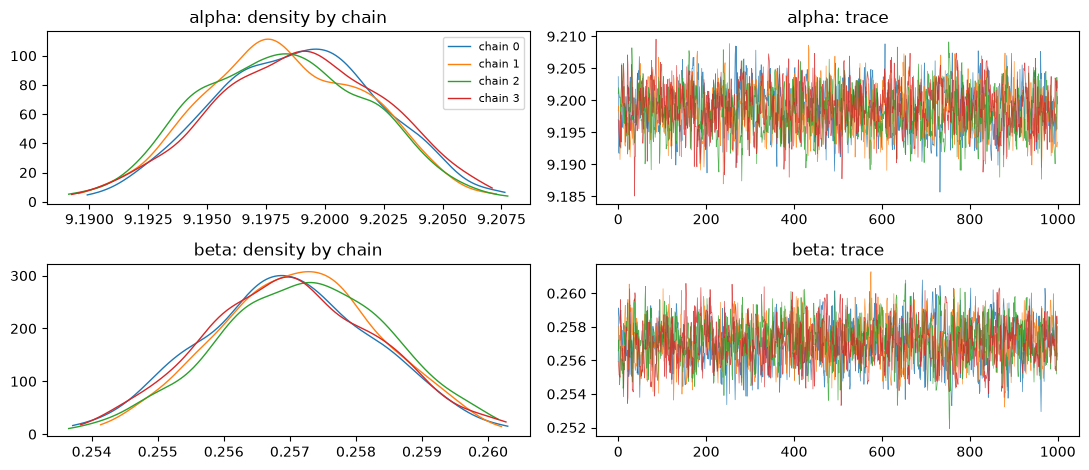

Divergent transitions: 0 (should be 0)


In [84]:
plot_trace(idata_pois, ["alpha", "beta"], "02_trace_poisson")

n_div = int(draws(idata_pois, "diverging", "sample_stats").sum())
print(f"Divergent transitions: {n_div} (should be 0)")

## 5. Posterior predictive check

Simulate new datasets from the fitted model and compare them with the real data.
If the real points often fall outside the simulated range, the model is
missing something.

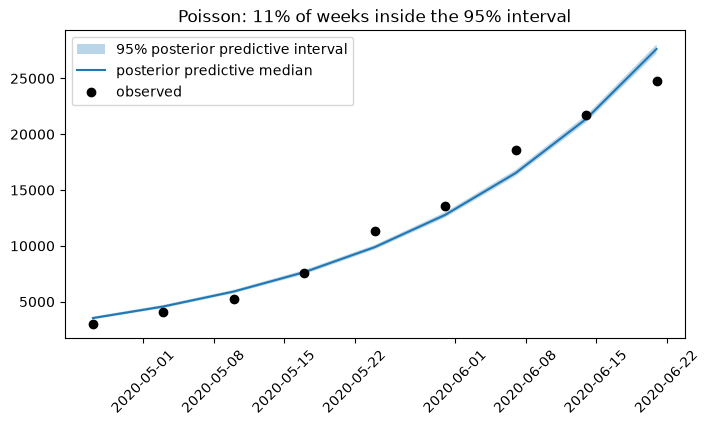

In [85]:
def plot_fit(idata, title, name):
    pp = draws(idata, "y", "posterior_predictive")  # (n_draws, n_weeks)
    lo, med, hi = np.percentile(pp, [2.5, 50, 97.5], axis=0)
    covered = np.mean((y >= lo) & (y <= hi))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.fill_between(weekly.index, lo, hi, alpha=0.3,
                    label="95% posterior predictive interval")
    ax.plot(weekly.index, med, label="posterior predictive median")
    ax.plot(weekly.index, y, "ko", label="observed")
    ax.set_title(f"{title}: {covered:.0%} of weeks inside the 95% interval")
    ax.legend()
    ax.tick_params(axis="x", rotation=45)
    save(fig, name)


plot_fit(idata_pois, "Poisson", "03_ppc_poisson")

Real case counts usually vary much more than a Poisson distribution allows
(variance = mean). This is **overdispersion**, caused by testing changes,
reporting delays and clustered outbreaks. If far fewer than 95% of the points
fall inside the interval, the Poisson model is too confident.

## 6. Negative Binomial model and model comparison

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta, inv_phi]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.
Sampling: [y]


                 mean     sd hdi95_lb hdi95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
alpha           9.182  0.054      9.1      9.3     2652     2032  1.00    0.0011   0.0017
beta           0.2775  0.022     0.23     0.32     2329     1773  1.00   0.00047  0.00059
inv_phi         0.026  0.031   0.0039    0.066     1405     1378  1.00    0.0008   0.0043
doubling_time   2.514   0.21      2.1      2.9     2329     1773  1.00    0.0047   0.0087


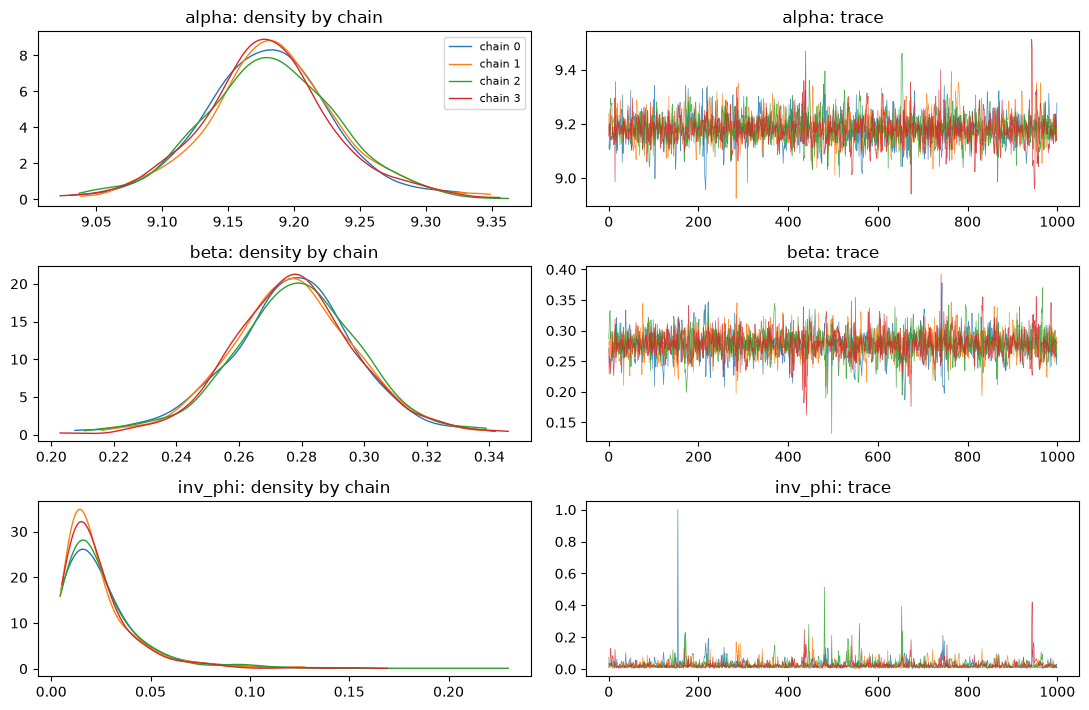

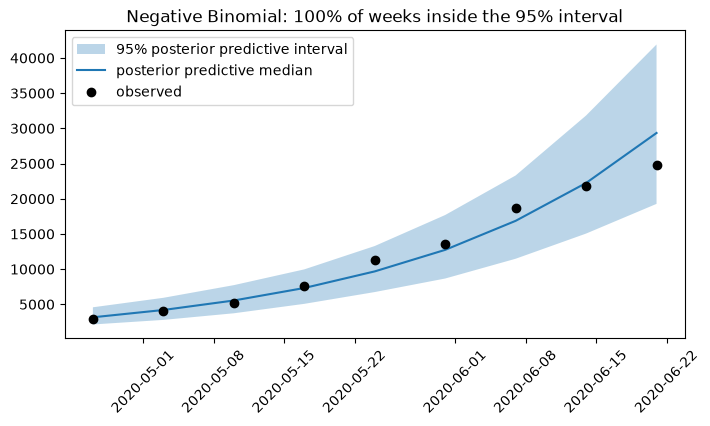

In [86]:
idata_nb = fit(build_model(y, "negbin"))
print(summarize(idata_nb, ["alpha", "beta", "inv_phi", "doubling_time"]))
plot_trace(idata_nb, ["alpha", "beta", "inv_phi"], "04_trace_negbin")
plot_fit(idata_nb, "Negative Binomial", "05_ppc_negbin")

In [87]:
comparison = az.compare({"Poisson": idata_pois, "NegBin": idata_nb})
print(comparison)

         rank  elpd_diff    dse  p_worse diag_diff    diag_elpd      p   elpd     se  weight
NegBin      0        0.0    0.0      NaN                           2.4  -78.0    3.3    0.96
Poisson     1     -600.0  180.0      1.0   N < 100  8 k̂ > 0.70  169.0 -700.0  200.0    0.04


e:\CANADA\bayesian-case-counts\.venv\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


`elpd_loo` estimates how well each model predicts a left-out week (higher is
better). If `elpd_diff` is much larger than its standard error `dse`, the
difference is meaningful. A `warning=True` means some weeks are very
influential, which is common with few data points; mention it as a limitation.

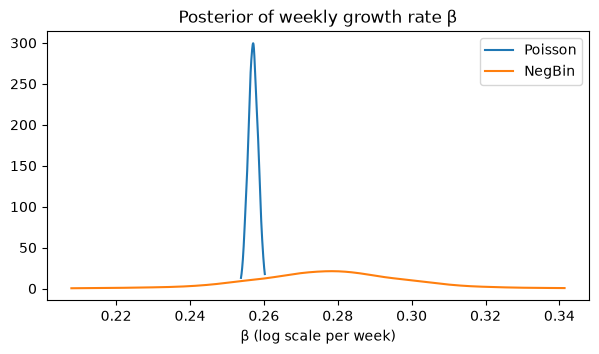

P(beta > 0 | data) = 1.000  (probability cases were growing)
Weekly growth factor: 1.32 (95% CI 1.26-1.38)


In [88]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, idata in [("Poisson", idata_pois), ("NegBin", idata_nb)]:
    density(ax, draws(idata, "beta"), label=name)
ax.set_title("Posterior of weekly growth rate β")
ax.set_xlabel("β (log scale per week)")
ax.legend()
save(fig, "06_beta_comparison")

beta_nb = draws(idata_nb, "beta")
print(f"P(beta > 0 | data) = {np.mean(beta_nb > 0):.3f}  (probability cases were growing)")
print(f"Weekly growth factor: {np.exp(np.median(beta_nb)):.2f} "
      f"(95% CI {np.exp(np.percentile(beta_nb, 2.5)):.2f}-"
      f"{np.exp(np.percentile(beta_nb, 97.5)):.2f})")

Notice that the Poisson interval for β is narrower. With overdispersed data
the Poisson model is **overconfident**; the Negative Binomial gives a more
honest measure of uncertainty.

## 7. Under-reporting: what the data cannot tell us

Reported cases are only a fraction $p$ of true infections:

$$y_t \sim \text{NegBin}(p \cdot \mu^{true}_t,\ \phi), \qquad
\log \mu^{true}_t = \alpha + \beta t, \qquad p \sim \text{Beta}(2, 6)$$

Here $p\,\mu^{true}_t = \exp(\log p + \alpha + \beta t)$, so the data only
inform the **sum** $\log p + \alpha$. Any increase in $p$ can be cancelled by
a decrease in $\alpha$. So $p$ and the true number of cases are
**not identifiable** from reported counts alone. The growth rate β, however,
is still identified.

In [93]:
model_ur = build_model(y, "negbin", detection_prior=(2, 6))
idata_ur = fit(model_ur)
with model_ur:
    prior_ur = pm.sample_prior_predictive(4000, random_seed=RNG_SEED)

print(summarize(idata_ur, ["alpha", "beta", "p"]))

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta, p, inv_phi]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 29 seconds.
Sampling: [y]
Sampling: [alpha, beta, inv_phi, p, y]


        mean     sd hdi95_lb hdi95_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha  10.61   0.59      9.6       12     1187     1182  1.00     0.018   0.016
beta   0.278  0.023     0.24     0.32     1766     1438  1.00   0.00056   0.001
p      0.279  0.143    0.037     0.56     1201     1182  1.00     0.004  0.0027


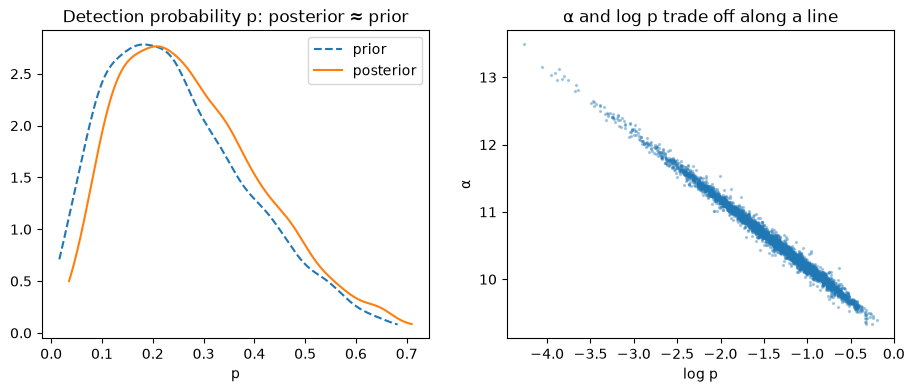

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
density(axes[0], draws(prior_ur, "p", "prior"), ls="--", label="prior")
density(axes[0], draws(idata_ur, "p"), label="posterior")
axes[0].set_title("Detection probability p: posterior ≈ prior")
axes[0].set_xlabel("p")
axes[0].legend()

axes[1].scatter(np.log(draws(idata_ur, "p")), draws(idata_ur, "alpha"),
                s=2, alpha=0.3)
axes[1].set_xlabel("log p")
axes[1].set_ylabel("α")
axes[1].set_title("α and log p trade off along a line")
save(fig, "07_identifiability")

**Interpretation**
* The posterior of $p$ is almost the same as its prior: the data contain
  no information about the detection probability.
* The scatter plot shows a near-perfect line: $\alpha + \log p$ is fixed by
  the data, but each part separately is not.
* β (growth) is unaffected by this problem.

### Sensitivity analysis
Because $p$ cannot be learnt from these data, the estimate of true cases is
driven by the assumption about $p$. We show this directly with fixed values:
true cases = expected reported cases / $p$.

In [95]:
mu_rep = draws(idata_nb, "mu_true")  # (n_draws, n_weeks), reported scale since p = 1
total_rep = mu_rep.sum(axis=1)
rows = []
for p_fixed in [1.0, 0.5, 0.25, 0.1]:
    total_true = total_rep / p_fixed
    rows.append({"assumed p": p_fixed,
                 "true cases (median)": f"{np.median(total_true):,.0f}",
                 "95% CI low": f"{np.percentile(total_true, 2.5):,.0f}",
                 "95% CI high": f"{np.percentile(total_true, 97.5):,.0f}"})
sensitivity = pd.DataFrame(rows)
print(f"Reported total in window: {y.sum():,}")
print(sensitivity.to_string(index=False))

Reported total in window: 109,850
 assumed p true cases (median) 95% CI low 95% CI high
      1.00             111,709     98,341     128,081
      0.50             223,417    196,682     256,162
      0.25             446,835    393,365     512,325
      0.10           1,117,087    983,412   1,280,812


The estimated number of true infections changes **10-fold** between p = 1 and
p = 0.1, while the data fit equally well in every case. Estimating p needs
**extra information**, for example:
* serology (antibody) surveys,
* testing data (positivity rates, number of tests),
* deaths or hospitalisations with a known infection-fatality ratio,
* multiple linked data sources, as in **capture-recapture** models, which
  estimate detection from how often the same individuals appear in
  different data sources.

## 8. Findings, limitations and uncertainty  (write this in your own words)

**Findings** – Report β (or the weekly growth factor and doubling time) with
its 95% credible interval from the Negative Binomial model, and
P(β > 0 | data).

**Limitations**
1. A single log-linear trend only fits one growth/decline phase. A random-walk
   or state-space model for $\log\mu_t$ would capture changing growth.
2. Reported counts are affected by testing volume, reporting delays and
   day-of-week effects (reduced here by weekly aggregation).
3. Few data points: LOO estimates can be unstable.
4. The prior on α is centred using the data.
5. True infections and detection probability are not identifiable from
   reported counts alone (section 7).

**Possible extensions**
* Random-walk (state-space) model for a time-varying growth rate.
* Use testing data as a covariate for the detection probability.
* Repeat the analysis in R (e.g., with `brms` or `cmdstanr`).

In [96]:
# Record package versions for reproducibility
import sys
print("Python", sys.version.split()[0])
for pkg in (pm, az, pd, np):
    print(pkg.__name__, pkg.__version__)

Python 3.13.16
pymc 6.4.0
arviz 1.3.0
pandas 3.1.1
numpy 2.5.5
